# 01 · Data and baseline

**Research question:** how does the reliability (discrimination, calibration, stability) of credit-risk models
degrade when credit-history information is missing, and when the remaining transactional data are sparse and noisy?

This notebook loads and checks the data, groups the features, makes a stratified split and fits the
**full-information baseline**. It then asks: *how much does credit history matter?*

In [1]:
import sys, os
from pathlib import Path
# Resolve the project root so the notebook runs from either the repo root or notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

# Project modules: data loading, feature groups and the baseline experiment
from src.data import load_data, split_data, HISTORY, TRANSACTIONAL, PROFILE_NUM, PROFILE_CAT, TARGET
from src.run_baseline import run as run_baseline

SYNTHETIC = False   # True = fake data, ONLY to check the code runs. Never report results from it.
if SYNTHETIC:
    print("WARNING: SYNTHETIC data in use. Do not interpret or report any number below.")

## 1. Load and check the data

In [2]:
df = load_data(synthetic=SYNTHETIC)
# Basic checks: size, class balance, and no missing values in the raw data
print("Rows, columns:", df.shape)
print("Default rate :", round(df[TARGET].mean(), 3))
print("Missing values in the raw data:", int(df.isna().sum().sum()), "(should be 0: we add missingness ourselves)")
df.head()

Rows, columns: (30000, 23)
Default rate : 0.221
Missing values in the raw data: 0 (should be 0: we add missingness ourselves)


,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,LIMIT_BAL,AGE,EDUCATION,MARRIAGE,default
0,2.0,2.0,-1.0,-1.0,-2.0,-2.0,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,20000.0,24.0,2,1,1
1,-1.0,2.0,0.0,0.0,0.0,2.0,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,120000.0,26.0,2,2,1
2,0.0,0.0,0.0,0.0,0.0,0.0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,90000.0,34.0,2,2,0
3,0.0,0.0,0.0,0.0,0.0,0.0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,50000.0,37.0,2,1,0
4,-1.0,0.0,-1.0,0.0,0.0,0.0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,50000.0,57.0,2,1,0


## 2. Feature groups (the research mapping)

| Group | Variables | Plays the role of |
|---|---|---|
| History | `PAY_0`, `PAY_2`-`PAY_6` | conventional credit history |
| Transactional | `BILL_AMT1-6`, `PAY_AMT1-6` | alternative transactional data (a proxy) |
| Profile | `LIMIT_BAL`, `AGE`, `EDUCATION`, `MARRIAGE` | application / profile data |

`SEX` is excluded from every model.

In [3]:
# Feature groups defined in src.data (see the table above)
for name, cols in [("History", HISTORY), ("Transactional", TRANSACTIONAL),
                   ("Profile (numeric)", PROFILE_NUM), ("Profile (categorical)", PROFILE_CAT)]:
    print(f"{name:22s} {len(cols):2d} columns: {cols}")

History                 6 columns: ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
Transactional          12 columns: ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
Profile (numeric)       2 columns: ['LIMIT_BAL', 'AGE']
Profile (categorical)   2 columns: ['EDUCATION', 'MARRIAGE']


## 3. A first look: is history informative?

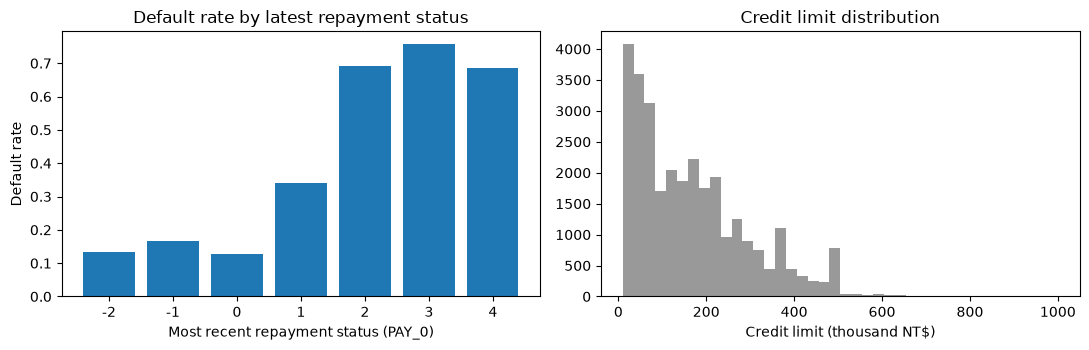

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
rate = df.groupby("PAY_0")[TARGET].agg(["mean", "size"])
# Drop repayment-status levels with fewer than 30 borrowers; their default rates are too noisy to plot
rate = rate[rate["size"] >= 30]
axes[0].bar(rate.index.astype(int).astype(str), rate["mean"], color="#1f77b4")
axes[0].set_xlabel("Most recent repayment status (PAY_0)"); axes[0].set_ylabel("Default rate")
axes[0].set_title("Default rate by latest repayment status")
# Right panel: distribution of credit limits
axes[1].hist(df["LIMIT_BAL"] / 1000, bins=40, color="#999")
axes[1].set_xlabel("Credit limit (thousand NT$)"); axes[1].set_title("Credit limit distribution")
plt.tight_layout(); plt.show()

## 4. Stratified train / validation / test split (60/20/20)

In [5]:
# Stratified 60/20/20 split; the default rate is preserved in each part
train, val, test = split_data(df, seed=0)
pd.DataFrame({"rows": [len(train), len(val), len(test)],
              "default_rate": [p[TARGET].mean() for p in (train, val, test)]},
             index=["train", "validation", "test"]).round(3)

,rows,default_rate
train,18000,0.221
validation,6000,0.221
test,6000,0.221


## 5. Baseline: how much does credit history matter?

Three logistic-regression models (L2), five random splits each:
full information · history removed · profile only. All preprocessing is fitted on training data only.

In [6]:
# Fit the three baselines over 5 random splits; `summary` gives the mean and std across splits
res, summary = run_baseline(seeds=5, df=df)
summary

auc          pr_auc         log_loss           brier         cal_slope             ece        
                                            mean     std    mean     std     mean     std    mean     std      mean     std    mean     std
features                                                                                                                                   
full (history + transactional + profile)  0.7181  0.0059  0.4997  0.0107   0.4682  0.0036  0.1458  0.0012    0.9716  0.0440  0.0541  0.0038
no history (transactional + profile)      0.6538  0.0070  0.3382  0.0069   0.5083  0.0040  0.1644  0.0007    0.8968  0.1277  0.0279  0.0043
profile only                              0.6130  0.0045  0.3012  0.0092   0.5157  0.0012  0.1678  0.0004    0.8871  0.0517  0.0161  0.0050

In [7]:
# Mean metrics per feature set
m = res.groupby("features", sort=False)[["auc", "brier", "cal_slope", "ece"]].mean()
# Change from full information to history removed (row order: full, no history, profile only)
change = (m.iloc[1] - m.iloc[0]).rename("change when history removed")
pd.concat([m.T, change], axis=1).round(4)

,full (history + transactional + profile),no history (transactional + profile),profile only,change when history removed
auc,0.7181,0.6538,0.6130,-0.0643
brier,0.1458,0.1644,0.1678,0.0186
cal_slope,0.9716,0.8968,0.8871,-0.0748
ece,0.0541,0.0279,0.0161,-0.0263


### Observations

- **Discrimination.** Removing credit history lowers mean AUC from 0.718 to 0.654 (a fall of 0.064); profile data
  alone gives 0.613. The split-to-split standard deviation is about 0.006-0.007, so the drop is far larger than
  sampling noise.
- **Calibration.** Brier score worsens from 0.146 to 0.164, and the calibration slope falls from 0.97 to 0.90 and
  becomes more variable across splits (std 0.044 to 0.128). A slope below 1 means predictions are more extreme
  than the observed outcomes justify. ECE moves the other way: it *improves* from 0.054 to 0.028, so the
  calibration metrics do not agree on direction.
- **Reading ECE with care.** A weaker model tends to produce predictions that sit closer to the overall default rate
  (22.1%), which can lower ECE without making the probabilities more reliable. This explanation was not tested here.
- **Link to H1** (calibration degrades before discrimination does): the baseline shows a large AUC loss when history
  is removed and mixed signals from the calibration metrics. H1 is tested directly under simulated missingness in
  notebook 04.